In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/telco_clean.csv")
print("Loaded:", df.shape)

Loaded: (7043, 21)


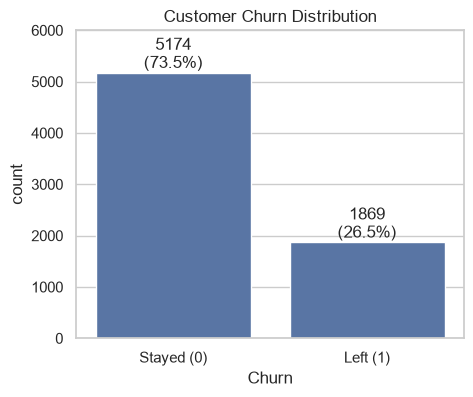

In [2]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Churn", data=df)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Stayed (0)", "Left (1)"])
plt.title("Customer Churn Distribution")

total = len(df)
for bar in ax.patches:
    pct = bar.get_height() / total * 100
    ax.annotate(f"{bar.get_height():.0f}\n({pct:.1f}%)",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")

plt.ylim(0, 6000)
plt.show()

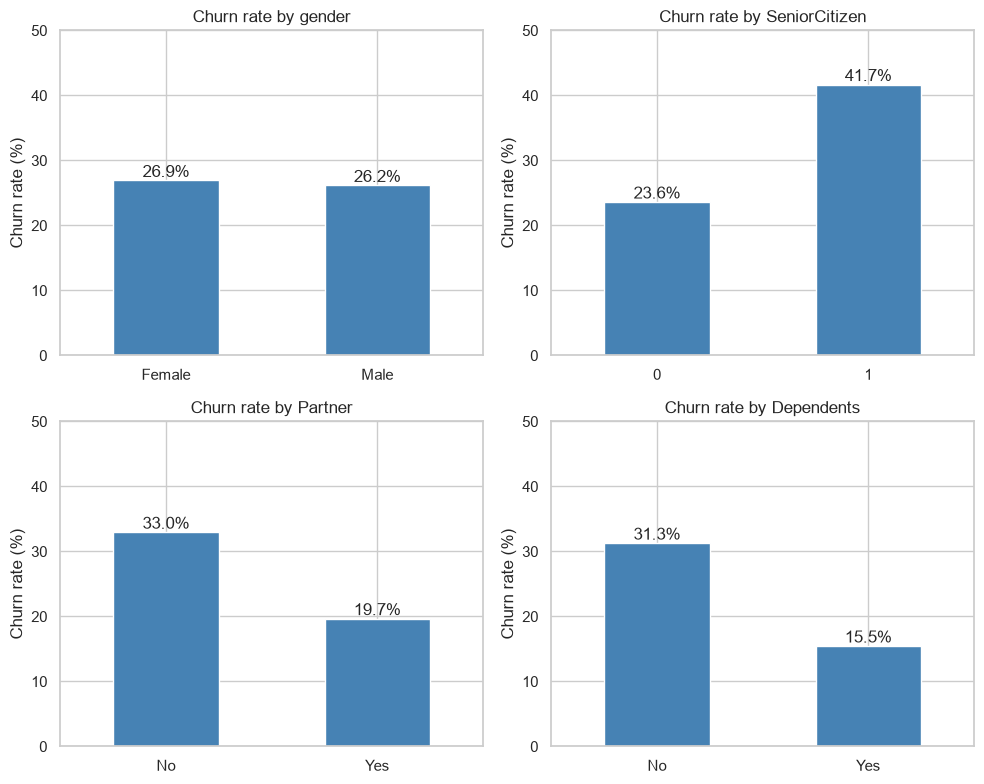

In [3]:
demo_cols = ["gender", "SeniorCitizen", "Partner", "Dependents"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for ax, col in zip(axes, demo_cols):
    rate = df.groupby(col)["Churn"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 50)
    ax.tick_params(axis="x", rotation=0)
    for bar in ax.patches:
        ax.annotate(f"{bar.get_height():.1f}%",
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom")

plt.tight_layout()
plt.show()

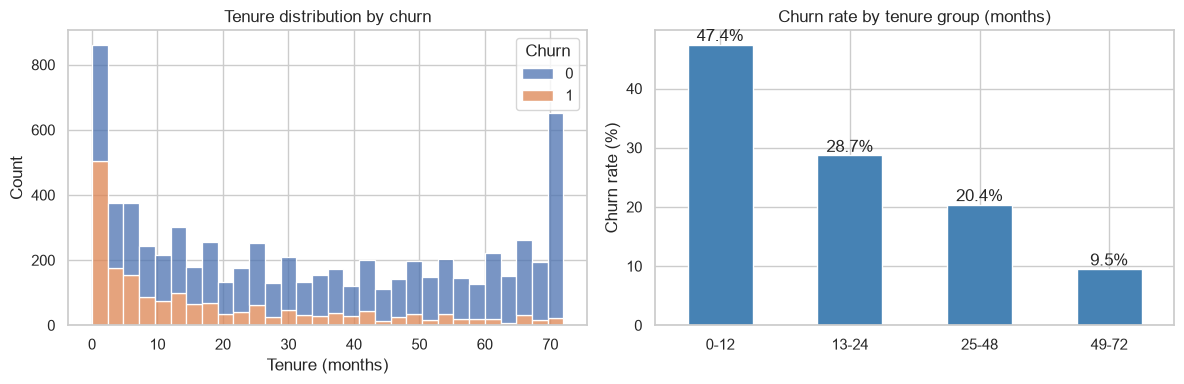

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack", ax=axes[0])
axes[0].set_title("Tenure distribution by churn")
axes[0].set_xlabel("Tenure (months)")

df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12", "13-24", "25-48", "49-72"])
rate = df.groupby("tenure_group", observed=True)["Churn"].mean() * 100
rate.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Churn rate by tenure group (months)")
axes[1].set_ylabel("Churn rate (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
for bar in axes[1].patches:
    axes[1].annotate(f"{bar.get_height():.1f}%",
                     (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     ha="center", va="bottom")

plt.tight_layout()
plt.show()

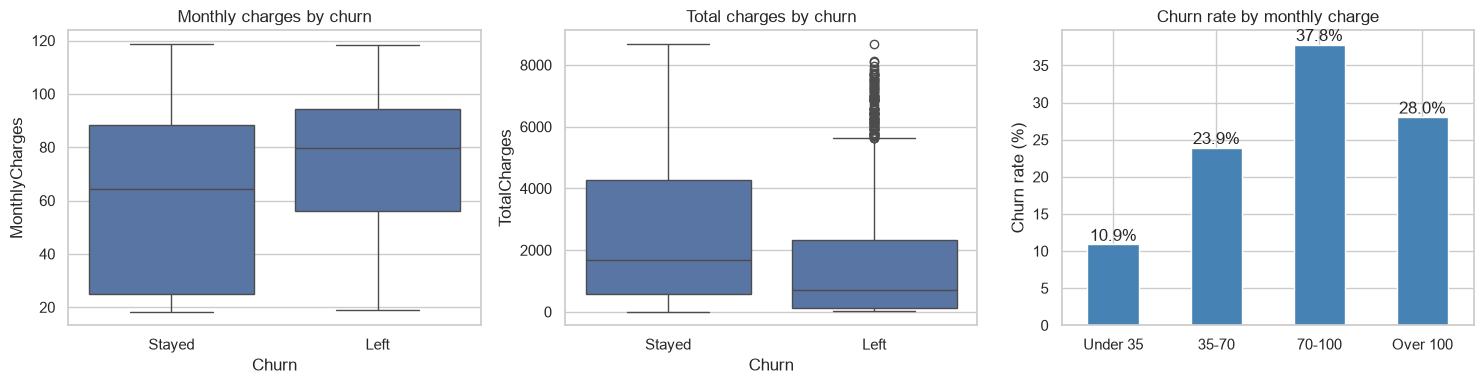

      MonthlyCharges        TotalCharges        
                mean median         mean  median
Churn                                           
0               61.3   64.4       2549.9  1679.5
1               74.4   79.6       1531.8   703.6


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[0])
axes[0].set_title("Monthly charges by churn")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Stayed", "Left"])

sns.boxplot(data=df, x="Churn", y="TotalCharges", ax=axes[1])
axes[1].set_title("Total charges by churn")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Stayed", "Left"])

df["charge_group"] = pd.cut(df["MonthlyCharges"], bins=[0, 35, 70, 100, 130],
                            labels=["Under 35", "35-70", "70-100", "Over 100"])
rate = df.groupby("charge_group", observed=True)["Churn"].mean() * 100
rate.plot(kind="bar", ax=axes[2], color="steelblue")
axes[2].set_title("Churn rate by monthly charge")
axes[2].set_ylabel("Churn rate (%)")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=0)
for bar in axes[2].patches:
    axes[2].annotate(f"{bar.get_height():.1f}%",
                     (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     ha="center", va="bottom")

plt.tight_layout()
plt.show()
print(df.groupby("Churn")[["MonthlyCharges", "TotalCharges"]].agg(["mean", "median"]).round(1))

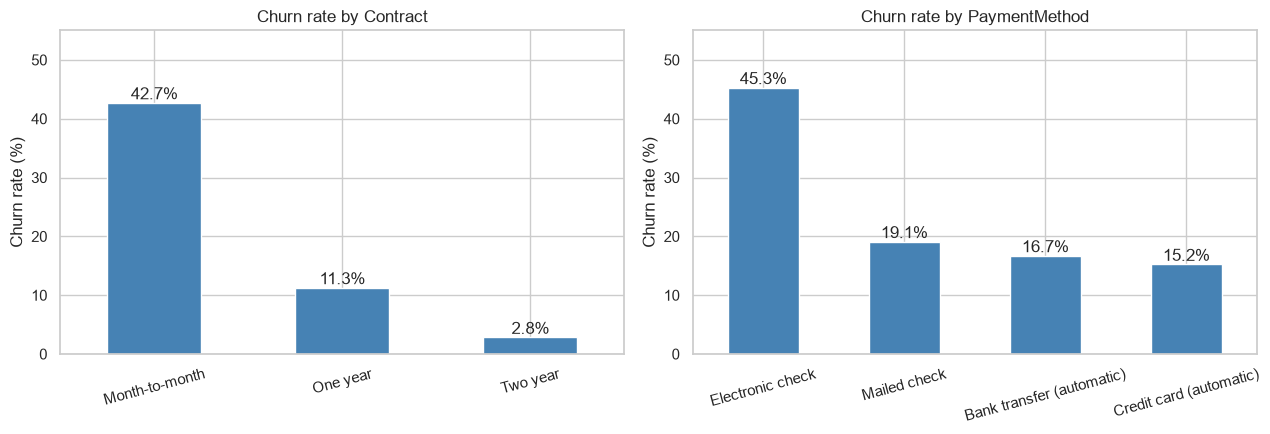

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, col in zip(axes, ["Contract", "PaymentMethod"]):
    rate = (df.groupby(col)["Churn"].mean() * 100).sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 55)
    ax.tick_params(axis="x", rotation=15)
    for bar in ax.patches:
        ax.annotate(f"{bar.get_height():.1f}%",
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom")

plt.tight_layout()
plt.show()

print(df["Contract"].value_counts())
print()
print(df["PaymentMethod"].value_counts())

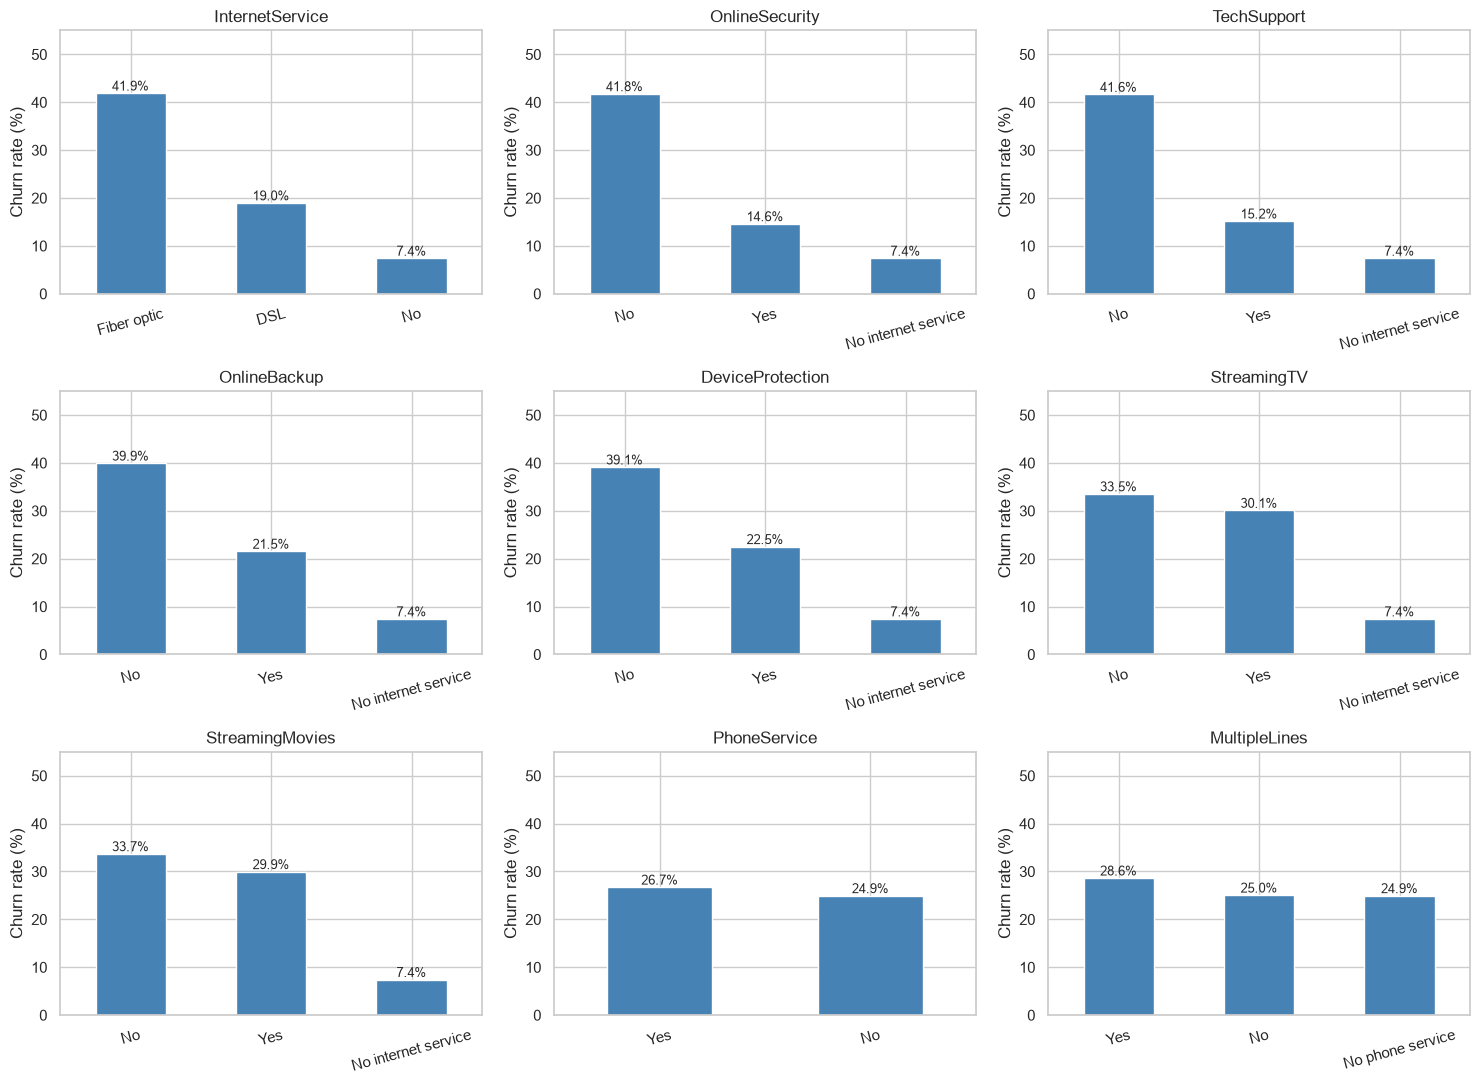

In [7]:
service_cols = ["InternetService", "OnlineSecurity", "TechSupport",
                "OnlineBackup", "DeviceProtection", "StreamingTV",
                "StreamingMovies", "PhoneService", "MultipleLines"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for ax, col in zip(axes, service_cols):
    rate = (df.groupby(col)["Churn"].mean() * 100).sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 55)
    ax.tick_params(axis="x", rotation=15)
    for bar in ax.patches:
        ax.annotate(f"{bar.get_height():.1f}%",
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

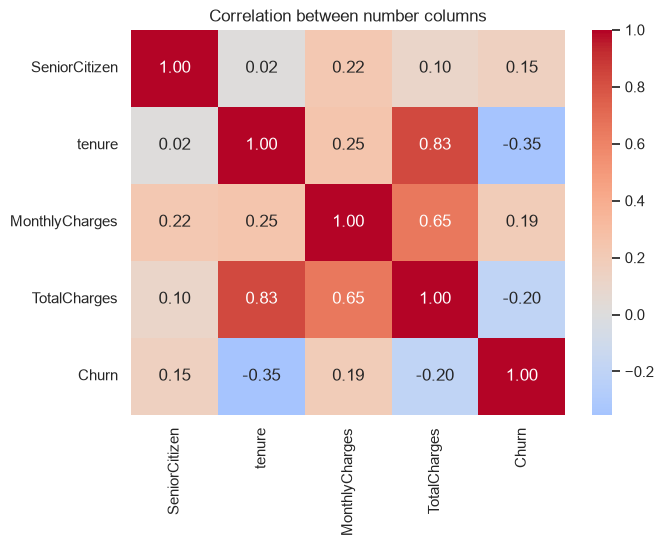

tenure           -0.352229
TotalCharges     -0.198324
SeniorCitizen     0.150889
MonthlyCharges    0.193356
Name: Churn, dtype: float64


In [8]:
num_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
corr = df[num_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between number columns")
plt.show()

print(corr["Churn"].drop("Churn").sort_values())